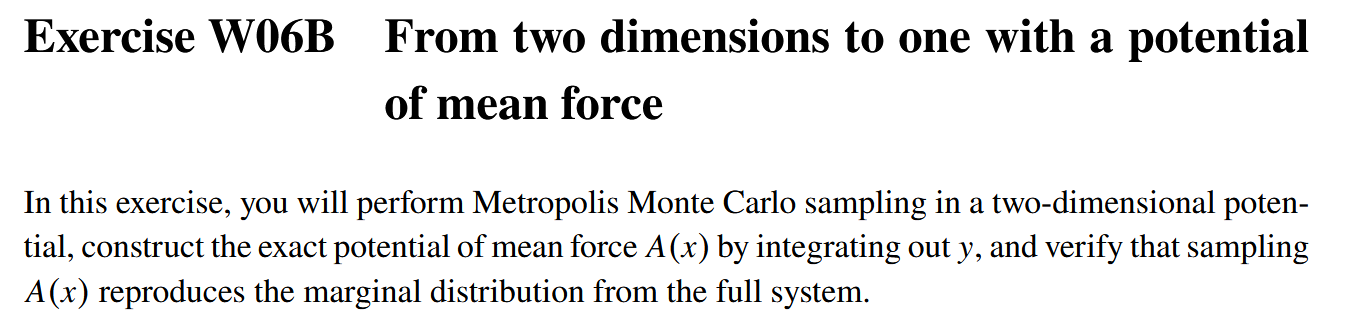
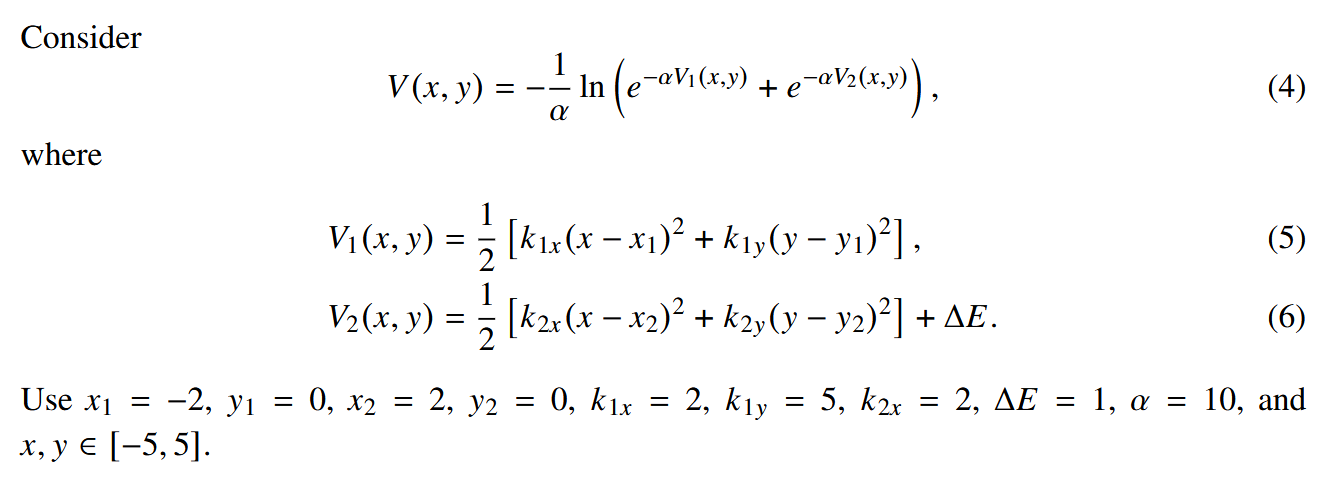
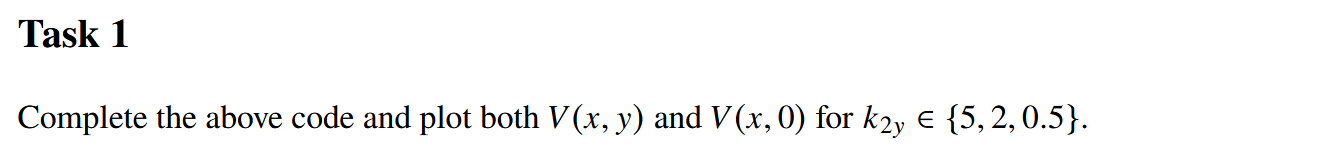

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

class Potential2D:
    xmin = -5
    xmax = 5
    ymin = -5
    ymax = 5

    @classmethod
    def limits(cls):
        return ([cls.xmin, cls.xmax], [cls.ymin, cls.ymax])

    x1, y1 = -2.0, 0.0
    x2, y2 = 2.0, 0.0

    def __init__ (self, k1x=2.0, k1y=5.0, k2x=2.0, k2y=0.5, deltaE=1, alpha=10.0):
        self.k1x = k1x
        self.k1y = k1y
        self.k2x = k2x
        self.k2y = k2y
        self.deltaE = deltaE
        self.a = alpha

    def V1(self, x, y):
        return 0.5 * (self.k1x * (x - self.x1)**2
                    + self.k1y * (y - self.y1)**2)
    
    def V2(self, x, y):
        return 0.5 * (self.k2x * (x - self.x2)**2
                    + self.k2y * (y - self.y2)**2) + self.deltaE
    
    def V(self, state):
        x, y = state
        return -1/self.a * np.log(np.exp(-self.a*self.V1(x, y)) 
                                + np.exp(-self.a*self.V2(x,y)))
    
    def contour_of_potential_energy(self, ax):
        Nc = 50
        Xs, Ys = np.meshgrid (
            np.linspace (self.xmin, self.xmax, Nc),
            np.linspace (self.ymin, self.ymax, Nc))

        Es = self.V([Xs, Ys])
        levels = np.geomspace(1, 10, 6)
        ax.contourf(Xs, Ys, Es, levels=levels, cmap=cm.YlGnBu)
        ax.contour(Xs, Ys, Es, levels=levels, colors='k')
        ax.set_title('V(x,y)')
        ax.set_xlabel('x')
        ax.set_ylabel('y')
    
    def plot1d(self, ax):
        xs = np.linspace(self.xmin, self.xmax, 1000)
        zs = self.V([xs, 0])
        ax.plot(xs, zs)
        ax.set_title('V(x ,0)')
        ax.set_ylim([-0.5, 13.5])

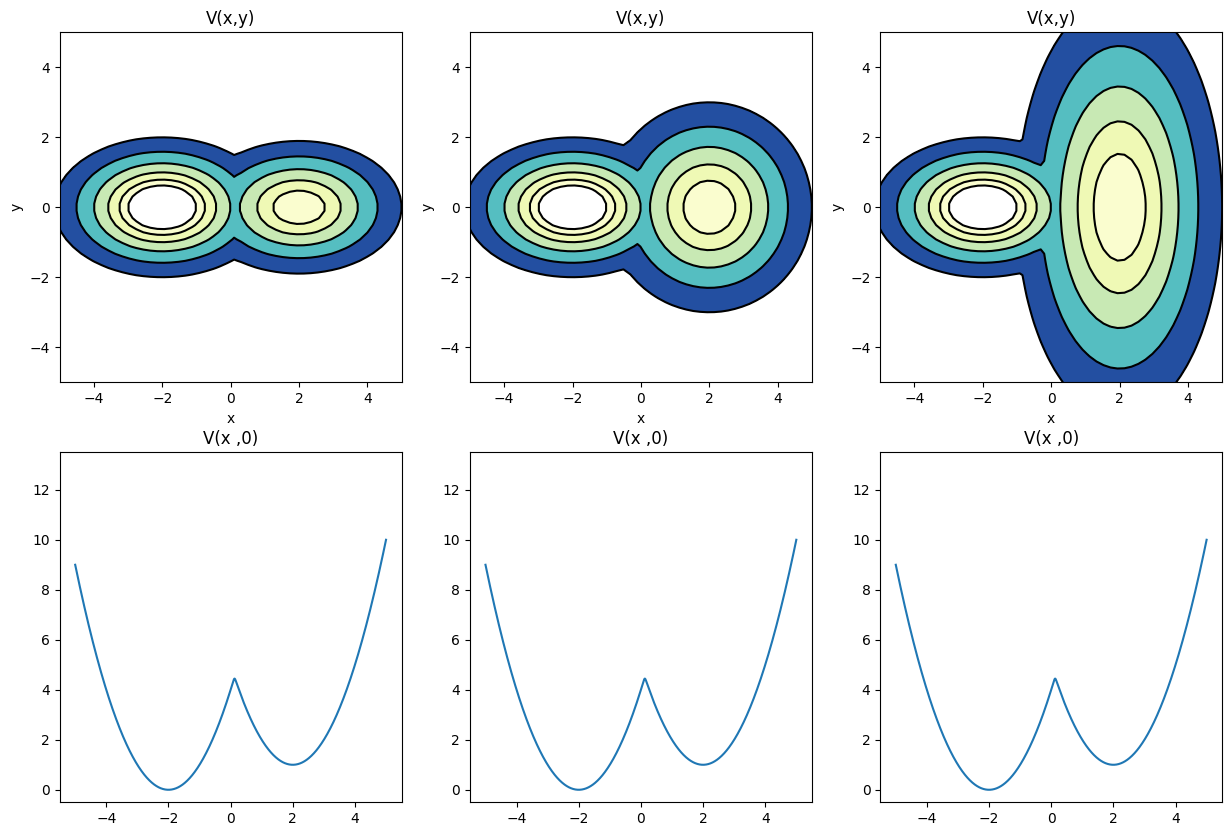

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

ky2_vals = [5, 2, 0.5]

for i, ky2 in enumerate(ky2_vals):
    pot = Potential2D(k2y=ky2)
    pot.contour_of_potential_energy(axes[i])
    pot.plot1d(axes[i+3])

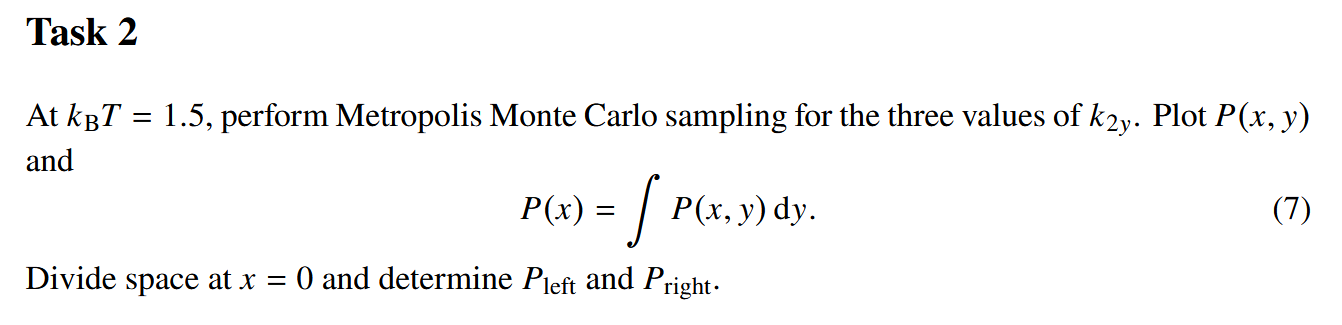

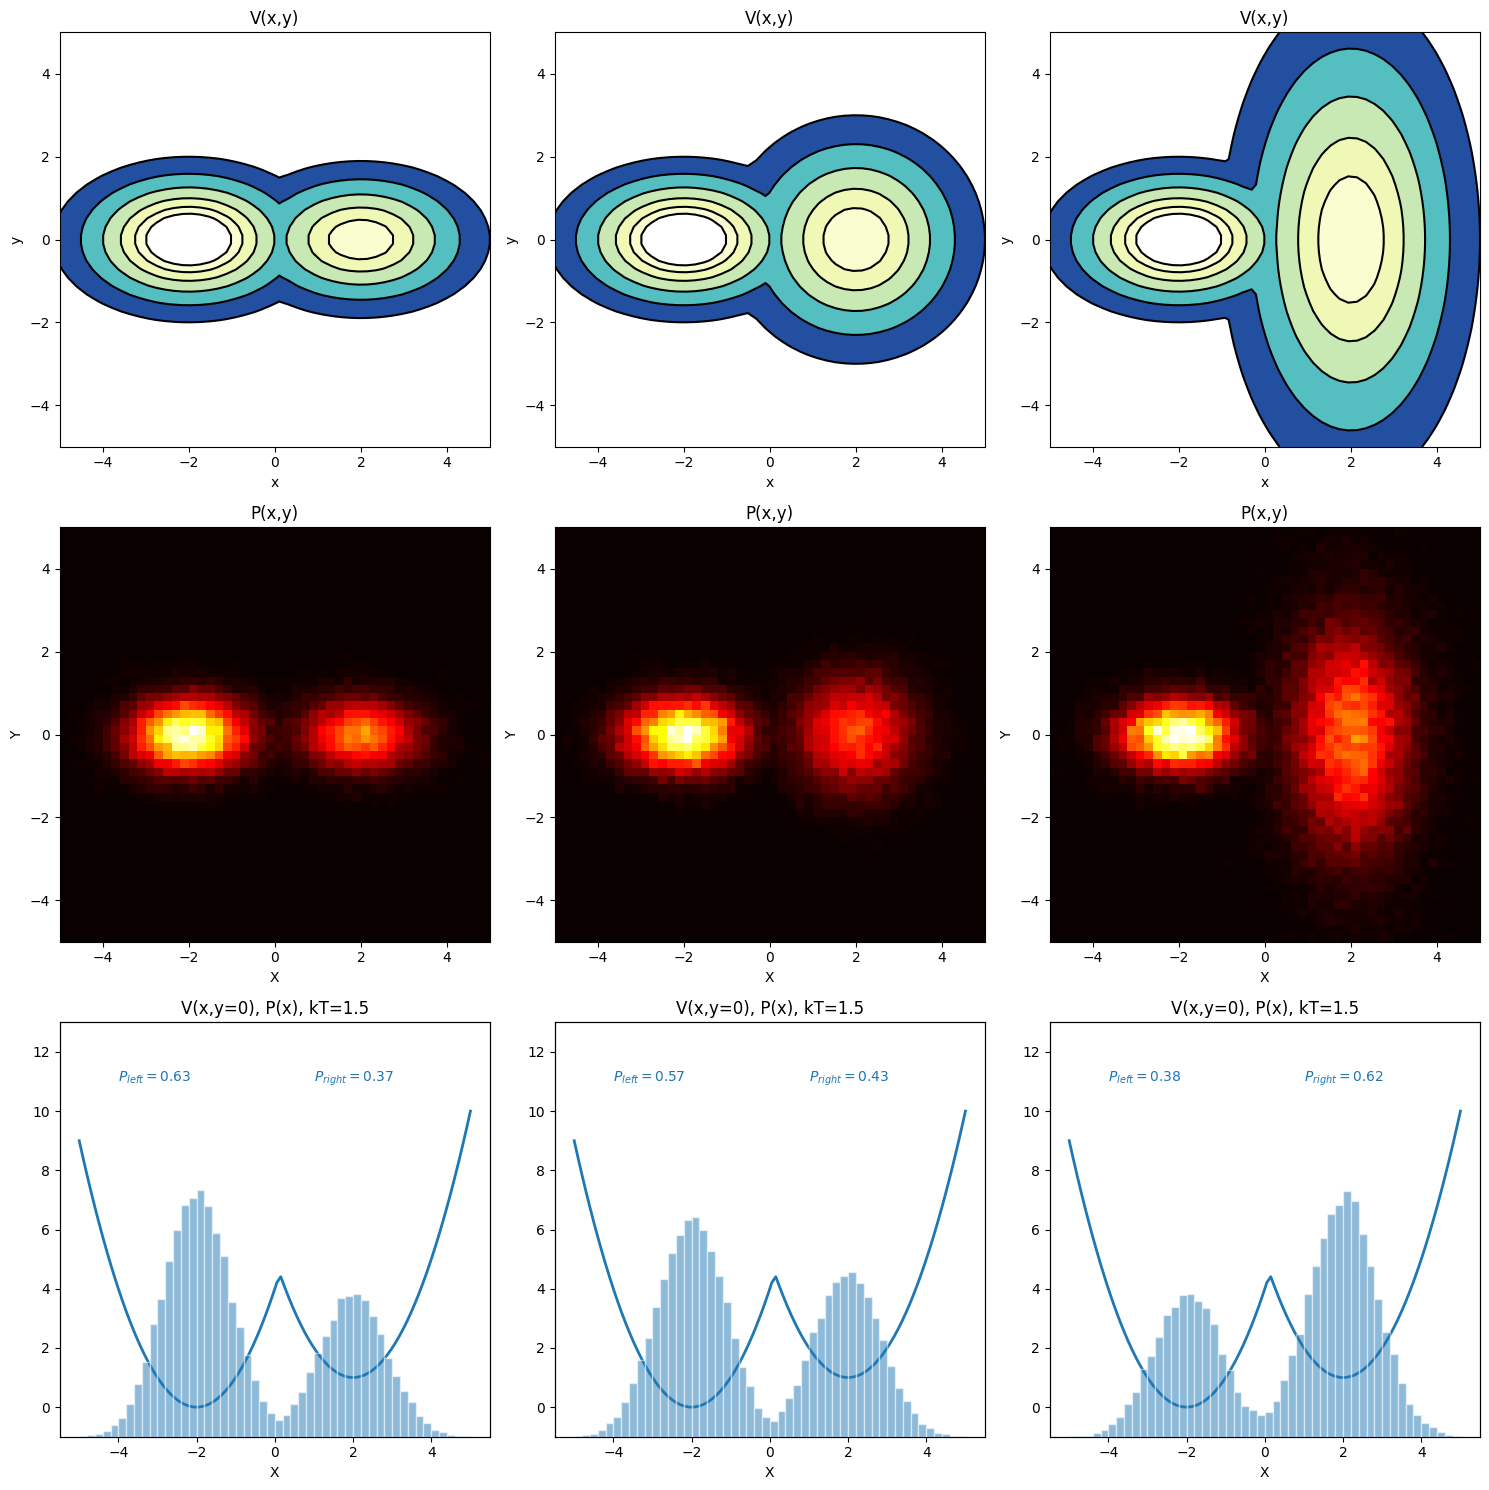

In [10]:
from Metropolis import *

class Potential2D(Potential2D):
    def plot1d(self, ax, x_vals):
        # Plot V(x, y=0) on the primary axis
        Vx_0 = [pot.V([x, 0]) for x in x_grid]
        ax.plot(x_grid, Vx_0, 'C0-', lw=2)
        ax.set_ylim(-1, 13)
        ax.set_title(f'V(x,y=0), P(x), kT={1.5}')
        ax.set_xlabel('X')

        # Calculate P_left and P_right
        P_left = np.sum(x_vals < 0) / len(x_vals)
        P_right = np.sum(x_vals >= 0) / len(x_vals)
        
        ax.text(-4, 11, f'$P_{{left}} = {P_left:.2f}$', color='C0', fontsize=10)
        ax.text(1, 11, f'$P_{{right}} = {P_right:.2f}$', color='C0', fontsize=10)
        
        # Plot the 1D histogram on a secondary y-axis 
        ax_twin = ax.twinx()
        ax_twin.hist(x_vals, bins=50, range=(-5, 5), density=True, alpha=0.5, edgecolor='white')
        ax_twin.set_ylim(0, 0.5) 
        ax_twin.set_yticks([])  
        

# Grid for contour plots
x_grid = np.linspace(-5, 5, 100)
y_grid = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x_grid, y_grid)

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.transpose().flatten()
for i, ky2 in enumerate(ky2_vals):
    pot = Potential2D(k2y=ky2)
    met = Metropolis(calc=pot, initial_state=[0.0, 0.0], kT=1.5, step_size=0.5)
    pos, energies = met.run(n_steps=100_000)

    # Extract x and y arrays
    x_vals = pos[:, 0]
    y_vals = pos[:, 1]
    
    pot.contour_of_potential_energy(axes[3 * i])

    ax_h = axes[3 * i + 1]
    ax_h.hist2d(x_vals, y_vals, bins=50, range=[[-5, 5], [-5, 5]], cmap='hot')
    ax_h.set_title('P(x,y)')
    ax_h.set_xlabel('X')
    ax_h.set_ylabel('Y')


    # --- Bottom Row: P(x) Histogram and V(x, y=0) ---
    pot.plot1d(axes[3 * i + 2], x_vals)
    
    

plt.tight_layout()
plt.show()

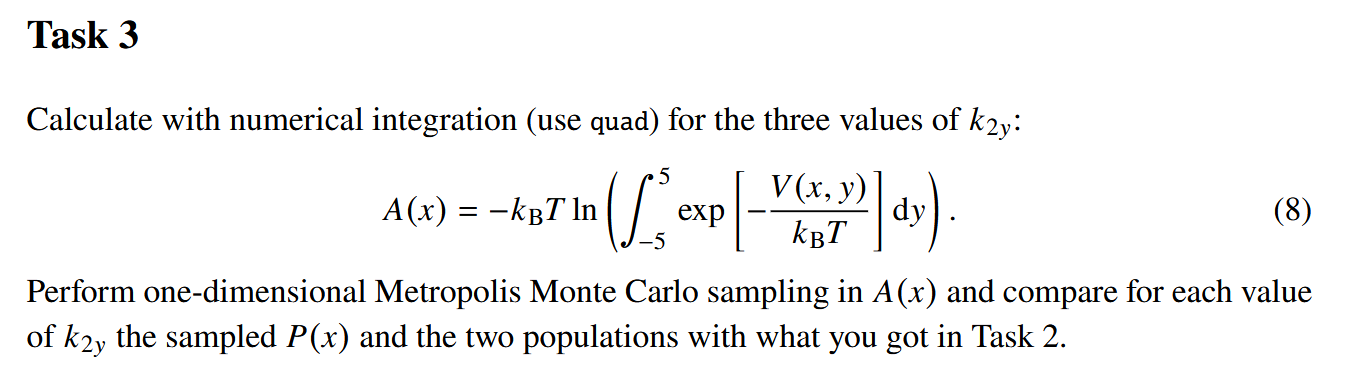

Sample size: 50000
Sample size: 50000
Sample size: 50000


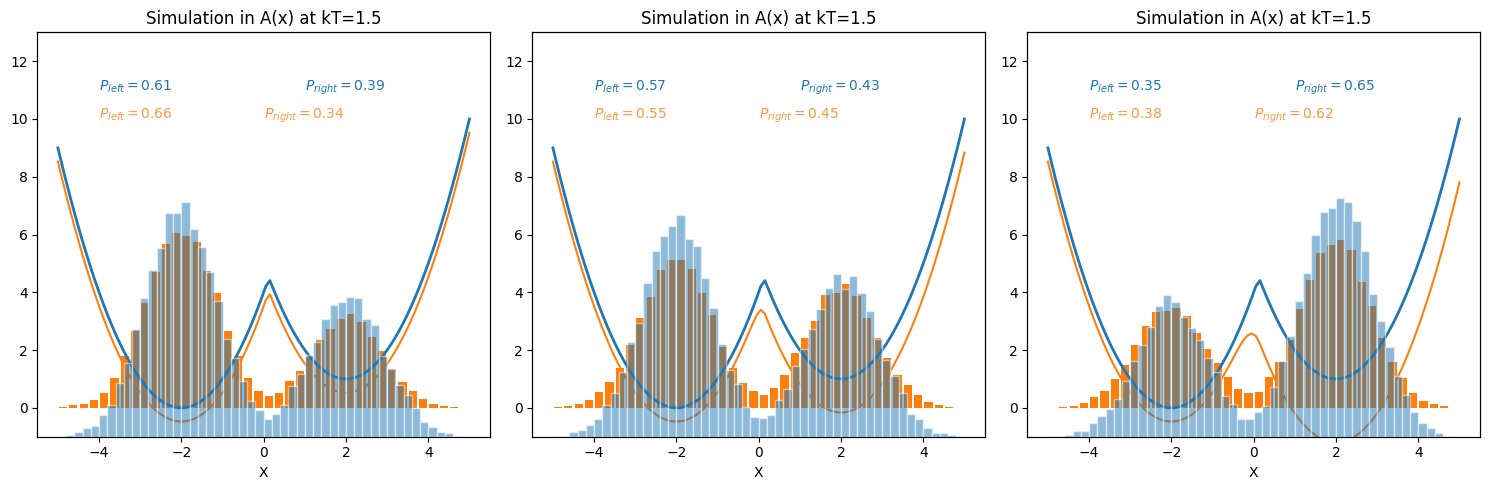

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.interpolate import interp1d
from week06 import MonteCarlo1D

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
kT = 1.5

for i, k2y in enumerate(ky2_vals):
    pot = Potential2D(deltaE=1.0, k2y=k2y)
    met = Metropolis(calc=pot, initial_state=[0.0, 0.0], kT=1.5, step_size=0.5)
    pos, energies = met.run(n_steps=50_000)
    x_vals = pos[:, 0]

    pot.plot1d(ax[i], x_vals)

    ylimits = pot.limits()[1]

    # Calculate A(x) = -kT * ln( integral( exp(-V(x,y)/kT) dy ) )
    a = lambda x: -kT * np.log(quad(lambda y: np.exp(-pot.V([x, y]) / kT), ylimits[0], ylimits[1])[0])

    xs = np.linspace(*pot.limits()[0], 100)
    avals = [a(x) for x in xs]

    # Interpolate to create a fast, continuous function for the Monte Carlo sampler
    a_approx = interp1d(xs, avals)

    monte_carlo_for_A = MonteCarlo1D(
        a_approx, 
        Nsim=50_000, 
        transition_method='uniform', 
        kT=kT
    )

    monte_carlo_for_A.plot(ax[i])

plt.tight_layout()    
plt.show()

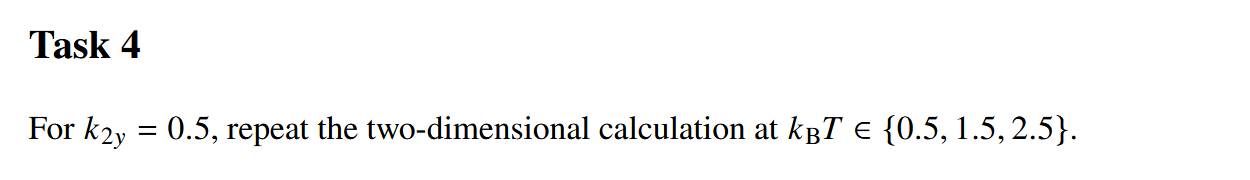

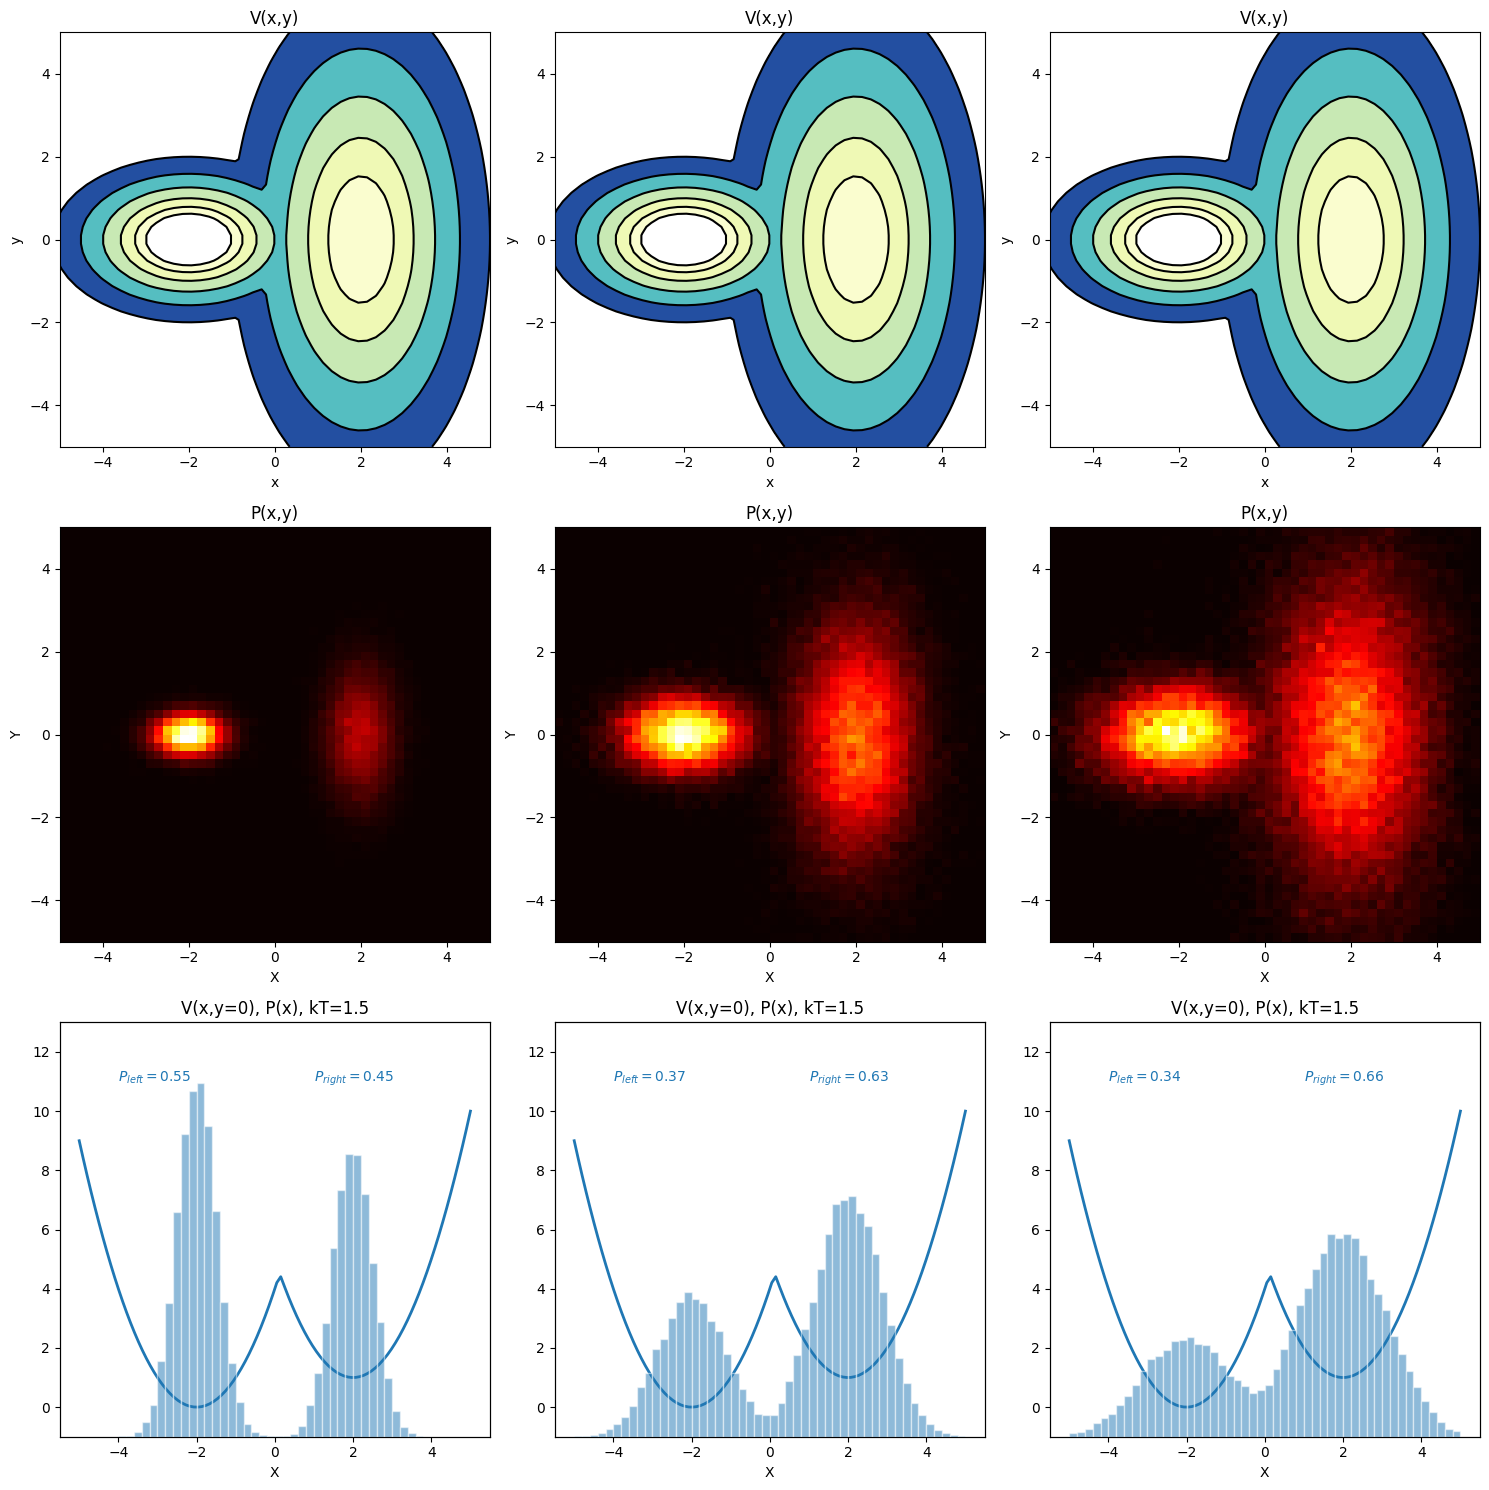

In [12]:
# Grid for contour plots
x_grid = np.linspace(-5, 5, 100)
y_grid = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x_grid, y_grid)

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.transpose().flatten()

kT_vals = [0.5, 1.5, 2.5]

for i, kT in enumerate(kT_vals):
    pot = Potential2D(k2y=0.5)
    met = Metropolis(calc=pot, initial_state=[0.0, 0.0], kT=kT, step_size=0.5)
    pos, energies = met.run(n_steps=100_000)

    # Extract x and y arrays
    x_vals = pos[:, 0]
    y_vals = pos[:, 1]
    
    pot.contour_of_potential_energy(axes[3 * i])

    ax_h = axes[3 * i + 1]
    ax_h.hist2d(x_vals, y_vals, bins=50, range=[[-5, 5], [-5, 5]], cmap='hot')
    ax_h.set_title('P(x,y)')
    ax_h.set_xlabel('X')
    ax_h.set_ylabel('Y')


    # --- Bottom Row: P(x) Histogram and V(x, y=0) ---
    pot.plot1d(axes[3 * i + 2], x_vals)
    

plt.tight_layout()
plt.show()

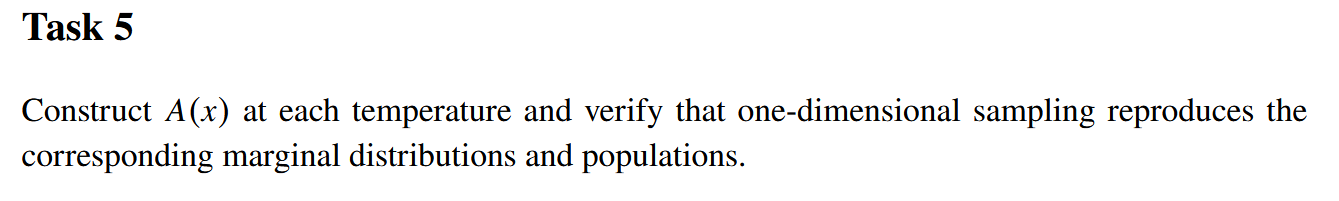

Sample size: 50000
Sample size: 50000
Sample size: 50000


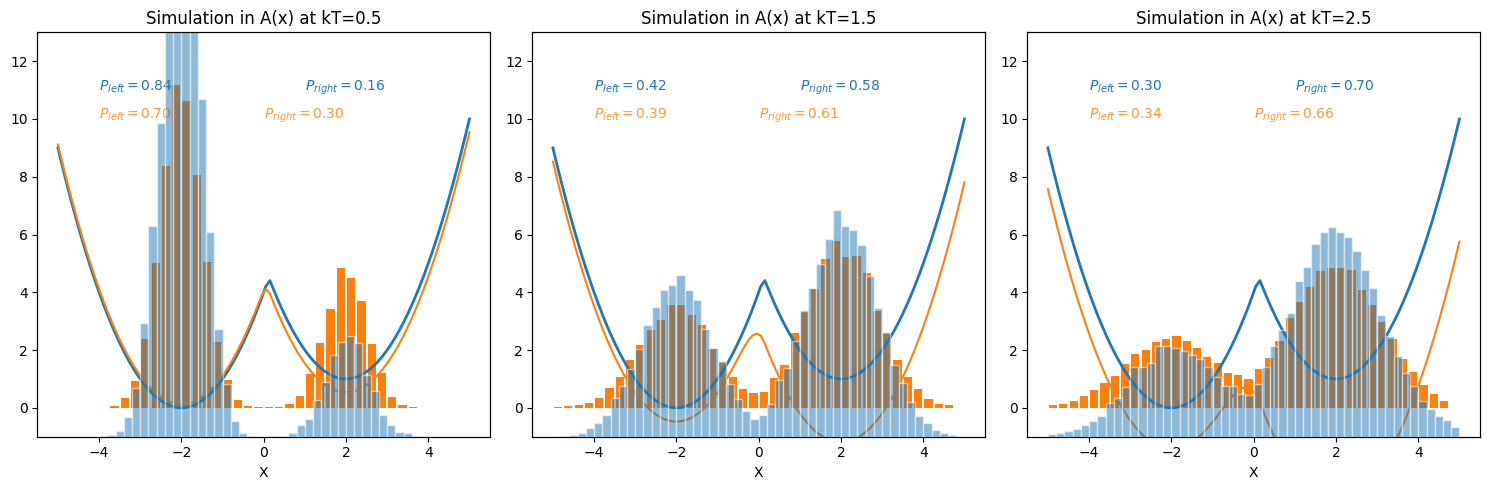

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
k2y = 0.5

for i, kT in enumerate(kT_vals):
    pot = Potential2D(deltaE=1.0, k2y=k2y)
    met = Metropolis(calc=pot, initial_state=[0.0, 0.0], kT=kT, step_size=0.5)
    pos, energies = met.run(n_steps=50_000)
    x_vals = pos[:, 0]

    pot.plot1d(ax[i], x_vals)

    ylimits = pot.limits()[1]

    # Calculate A(x) = -kT * ln( integral( exp(-V(x,y)/kT) dy ) )
    a = lambda x: -kT * np.log(quad(lambda y: np.exp(-pot.V([x, y]) / kT), ylimits[0], ylimits[1])[0])

    xs = np.linspace(*pot.limits()[0], 100)
    avals = [a(x) for x in xs]

    # Interpolate to create a fast, continuous function for the Monte Carlo sampler
    a_approx = interp1d(xs, avals)

    monte_carlo_for_A = MonteCarlo1D(
        a_approx, 
        Nsim=50_000, 
        transition_method='uniform', 
        kT=kT
    )

    monte_carlo_for_A.plot(ax[i])

plt.tight_layout()    
plt.show()